<a href="https://colab.research.google.com/github/kunjpatel00987/Machine-learning/blob/main/Machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(1000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    object 
 1   details            1000 non-null   object 
 2   Catatory           997 non-null    object 
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    object 
 5   available          889 non-null    float64
 6   text               997 non-null    object 
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    object 
 9   itemLocation       1000 non-null   object 
dtypes: float64(3), object(7)
memory usage: 78.3+ KB


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


,price,available,sold
count,995.000000,889.000000,992.000000
mean,46.433467,20.046119,775.246976
std,35.551712,61.547985,3211.433298
min,3.000000,2.000000,1.000000
25%,22.990000,5.000000,14.000000
50%,35.710000,10.000000,49.500000
75%,59.000000,10.000000,324.750000
max,259.090000,842.000000,54052.000000


Item_Name              1
details                0
Catatory               3
price                  5
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
itemLocation           0
dtype: int64
Duplicates: 0


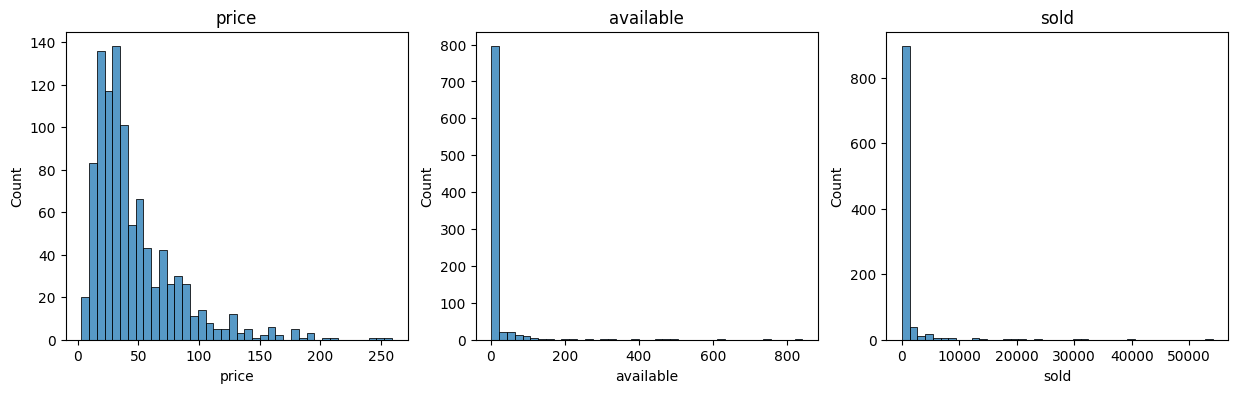

price        2.043529
available    8.161836
sold         9.714312
dtype: float64


In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("/content/Sales-[5444].csv", encoding="utf-8-sig")

print(df.shape)
df.info()
display(df.head())
display(df.describe())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

# distributions: you should see them very skewed
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["price", "available", "sold"]):
    sns.histplot(df[c].dropna(), bins=40, ax=a); a.set_title(c)
plt.show()
print(df[["price", "available", "sold"]].skew())

In [ ]:
# 1) Recover price from priceWithCurrency (e.g. "US $84.99/ea")
p = df["priceWithCurrency"].str.extract(r"\$([\d,]+\.?\d*)")[0].str.replace(",", "").astype(float)
df["price"] = df["price"].fillna(p)

# 2) Recover sold from the text column ("... / 116 sold")
s = df["text"].str.extract(r"(\d[\d,]*)\s+sold")[0].str.replace(",", "").astype(float)
df["sold"] = df["sold"].fillna(s)

# 3) available: "Last One" means 1, otherwise fill with the median
df.loc[df["text"].str.contains("Last One", na=False) & df["available"].isna(), "available"] = 1
df["available"] = df["available"].fillna(df["available"].median())

# 4) Clean categories
df["Catatory"] = (df["Catatory"].str.lower().str.strip()
                  .replace({"/": np.nan, "eau de perfume": "eau de parfum"}))
df["Catatory"] = df["Catatory"].fillna("unknown")
top = df["Catatory"].value_counts().head(6).index
df["category"] = df["Catatory"].where(df["Catatory"].isin(top), "other")

# 5) Dates -> "days since last update", measured from the newest date in the data
d = pd.to_datetime(df["lastUpdated"].str.replace(r" P[SD]T", "", regex=True),
                   format="%b %d, %Y %H:%M:%S", errors="coerce")
df["days_since_update"] = (d.max() - d).dt.days
df["days_since_update"] = df["days_since_update"].fillna(df["days_since_update"].median())

# 6) Location -> state, with rare ones grouped
df["state"] = df["itemLocation"].str.split(",").str[-2].str.strip()
top_states = df["state"].value_counts().head(8).index
df["state"] = df["state"].where(df["state"].isin(top_states), "Other")

# 7) Drop the few rows still missing sold, then re-check
df = df.dropna(subset=["sold"]).reset_index(drop=True)
print(df.isnull().sum())

Item_Name             1
details               0
Catatory              0
price                 0
priceWithCurrency     1
available             0
text                  0
sold                  0
lastUpdated          47
itemLocation          0
category              0
days_since_update     0
state                 0
dtype: int64


price        1.965599
available    8.623509
sold         9.724094
revenue      8.693321
dtype: float64
log_price        0.086332
log_available    1.580399
log_sold         0.536274
log_revenue      0.335936
dtype: float64


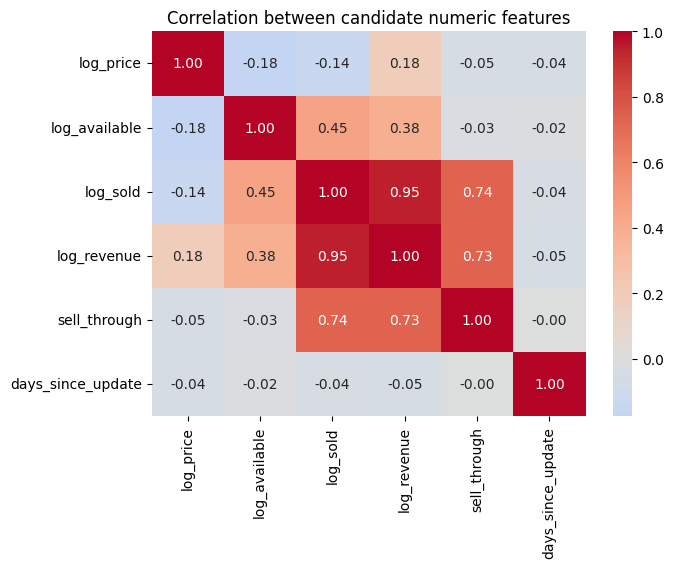

In [ ]:
# Engineered features
df["revenue"]      = df["price"] * df["sold"]
df["sell_through"] = df["sold"] / (df["sold"] + df["available"])

# Log-transform the skewed columns (log1p handles zeros safely)
for c in ["price", "available", "sold", "revenue"]:
    df["log_" + c] = np.log1p(df[c])

# Check skew before vs after, and screenshot this
print(df[["price","available","sold","revenue"]].skew())
print(df[["log_price","log_available","log_sold","log_revenue"]].skew())

# Correlation heatmap, and screenshot this too
cols = ["log_price","log_available","log_sold","log_revenue","sell_through","days_since_update"]
plt.figure(figsize=(7,5))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation between candidate numeric features")
plt.show()

In [ ]:
num_features = ["log_price", "log_sold", "log_available", "days_since_update"]
X_num = df[num_features]
X_cat = pd.get_dummies(df["category"], prefix="cat", dtype=int)
X = pd.concat([X_num, X_cat], axis=1)
print(X.shape); display(X.head())

(994, 11)


,log_price,log_sold,log_available,days_since_update,cat_eau de cologne,cat_eau de parfum,cat_eau de toilette,cat_fragrances,cat_other,cat_parfum,cat_perfume
0,4.454231,4.762174,2.397895,0.0,0,1,0,0,0,0,0
1,4.709440,3.891820,2.197225,0.0,0,1,0,0,0,0,0
2,4.615121,3.332205,2.397895,1.0,0,0,1,0,0,0,0
3,3.828424,5.075174,1.098612,0.0,0,0,1,0,0,0,0
4,2.885359,5.056246,2.302585,0.0,0,0,0,1,0,0,0


In [ ]:
df["revenue"]      = df["price"] * df["sold"]
df["sell_through"] = df["sold"] / (df["sold"] + df["available"])

for c in ["price", "available", "sold", "revenue", "days_since_update"]:
    df["log_" + c] = np.log1p(df[c])

print(df[["price","available","sold","revenue","days_since_update"]].skew())
print(df[["log_price","log_available","log_sold","log_revenue","log_days_since_update"]].skew())

price                 1.965599
available             8.623509
sold                  9.724094
revenue               8.693321
days_since_update    13.281732
dtype: float64
log_price                0.086332
log_available            1.580399
log_sold                 0.536274
log_revenue              0.335936
log_days_since_update    1.157392
dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

num_features = ["log_price", "log_sold", "log_available", "log_days_since_update"]
X_num = df[num_features]

# Categorical -> one-hot (0/1)
X_cat = pd.get_dummies(df["category"], prefix="cat", dtype=int)

# Standardisation (mean 0, std 1) -> used for the clustering models
scaler = StandardScaler()
X_num_scaled = pd.DataFrame(scaler.fit_transform(X_num), columns=num_features)

# Normalisation (0-1) -> for comparison only
X_num_minmax = pd.DataFrame(MinMaxScaler().fit_transform(X_num), columns=num_features)

# Final matrix used by K-Means, Hierarchical and DBSCAN
X_final = pd.concat([X_num_scaled, X_cat.reset_index(drop=True)], axis=1)
print(X_final.shape)           # expect (994, 11)

print(X_num_scaled.describe().round(2))   # screenshot: mean ~0, std ~1
print(X_num_minmax.describe().round(2))   # screenshot: min 0, max 1

(994, 11)
       log_price  log_sold  log_available  log_days_since_update
count     994.00    994.00         994.00                 994.00
mean       -0.00      0.00          -0.00                   0.00
std         1.00      1.00           1.00                   1.00
min        -3.35     -1.74          -1.66                  -0.92
25%        -0.67     -0.77          -0.66                  -0.92
50%        -0.04     -0.18           0.10                  -0.34
75%         0.70      0.72           0.20                   0.58
max         2.89      3.19           4.95                   4.41
       log_price  log_sold  log_available  log_days_since_update
count     994.00    994.00         994.00                 994.00
mean        0.54      0.35           0.25                   0.17
std         0.16      0.20           0.15                   0.19
min         0.00      0.00           0.00                   0.00
25%         0.43      0.20           0.15                   0.00
50%         0.5

,k,inertia,silhouette,davies_bouldin,calinski
0,2,3663.550,0.206,1.760,268.598
1,3,3049.274,0.204,1.554,261.010
2,4,2635.335,0.207,1.478,252.978
3,5,2287.796,0.206,1.408,255.887
4,6,2127.280,0.193,1.488,234.844
5,7,1994.620,0.194,1.521,219.448
6,8,1903.255,0.184,1.541,203.690
7,9,1809.756,0.181,1.480,193.608
8,10,1737.574,0.180,1.469,183.605


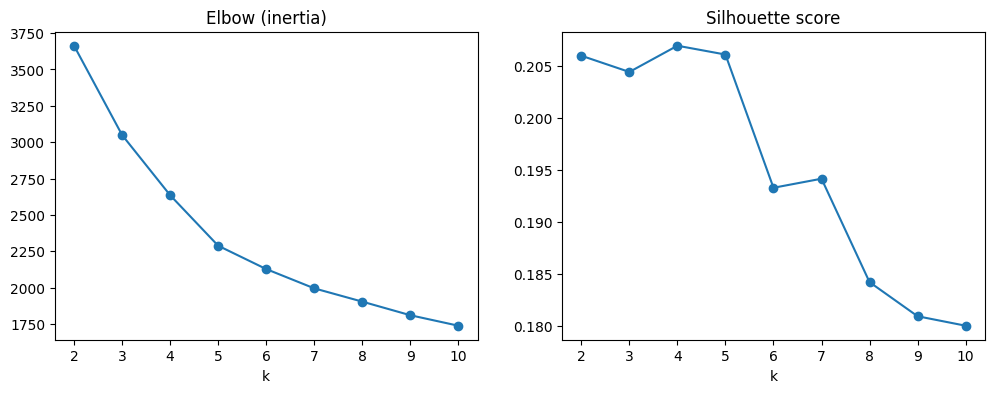

km_cluster
0    271
1     77
2    225
3    174
4    247
Name: count, dtype: int64


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

X = X_final.values
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append([k, km.inertia_, silhouette_score(X, km.labels_),
                 davies_bouldin_score(X, km.labels_), calinski_harabasz_score(X, km.labels_)])
km_scores = pd.DataFrame(rows, columns=["k","inertia","silhouette","davies_bouldin","calinski"])
display(km_scores.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(km_scores.k, km_scores.inertia, "o-"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(km_scores.k, km_scores.silhouette, "o-"); ax[1].set_title("Silhouette score")
for a in ax: a.set_xlabel("k")
plt.show()

km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X)
df["km_cluster"] = km.labels_
print(df["km_cluster"].value_counts().sort_index())

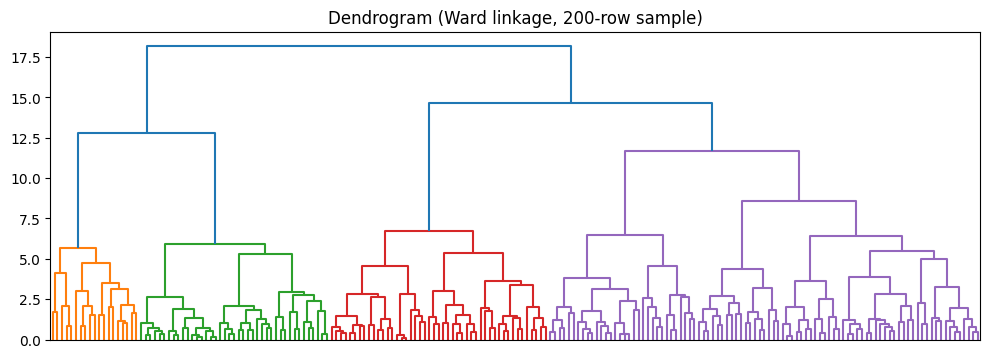

hc_cluster
0    349
1    256
2    122
3     74
4    193
Name: count, dtype: int64
0.15859731249529618 1.5576342520894548 200.93903120059562


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Dendrogram on a sample (readable)
sample = X[np.random.RandomState(42).choice(len(X), 200, replace=False)]
plt.figure(figsize=(12, 4))
dendrogram(linkage(sample, method="ward"), no_labels=True)
plt.title("Dendrogram (Ward linkage, 200-row sample)"); plt.show()

# Full-data model, same k as K-Means for a fair comparison
hc = AgglomerativeClustering(n_clusters=5, linkage="ward").fit(X)
df["hc_cluster"] = hc.labels_
print(df["hc_cluster"].value_counts().sort_index())
print(silhouette_score(X, hc.labels_), davies_bouldin_score(X, hc.labels_), calinski_harabasz_score(X, hc.labels_))

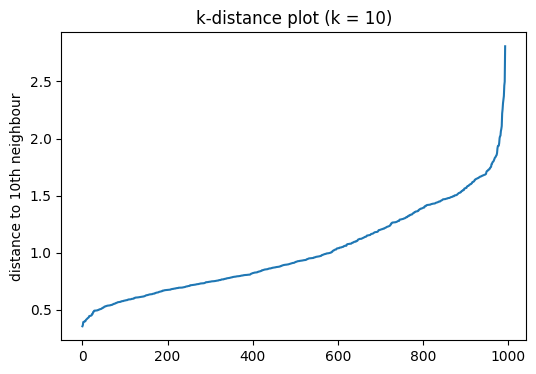

0.8 5 clusters: 13 noise: 281
0.8 10 clusters: 7 noise: 411
1.0 5 clusters: 11 noise: 153
1.0 10 clusters: 5 noise: 259
1.2 5 clusters: 8 noise: 78
1.2 10 clusters: 7 noise: 149
1.5 5 clusters: 1 noise: 20
1.5 10 clusters: 1 noise: 30
0.0898066473192695 1.5027009939899294 56.20610331038589


In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

ms = 10
kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1])
plt.figure(figsize=(6, 4)); plt.plot(kd)
plt.title("k-distance plot (k = 10)"); plt.ylabel("distance to 10th neighbour"); plt.show()

for eps in [0.8, 1.0, 1.2, 1.5]:
    for m in [5, 10]:
        l = DBSCAN(eps=eps, min_samples=m).fit_predict(X)
        print(eps, m, "clusters:", len(set(l)) - (1 if -1 in l else 0), "noise:", (l == -1).sum())

db = DBSCAN(eps=1.0, min_samples=10).fit(X)
df["db_cluster"] = db.labels_
mask = db.labels_ != -1                       # exclude noise for the metrics
print(silhouette_score(X[mask], db.labels_[mask]),
      davies_bouldin_score(X[mask], db.labels_[mask]),
      calinski_harabasz_score(X[mask], db.labels_[mask]))

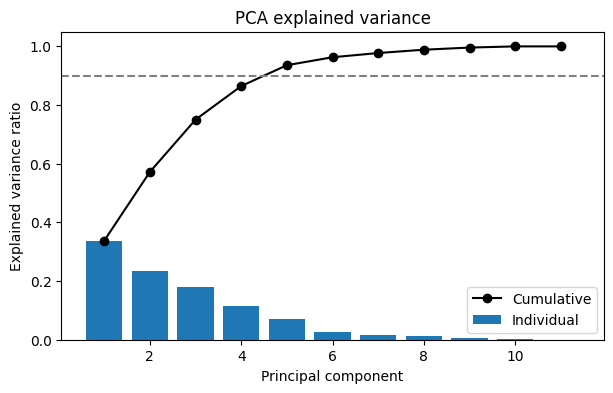

[0.337 0.235 0.178 0.114 0.071 0.027 0.014 0.011 0.007 0.004 0.   ]
[0.337 0.572 0.75  0.865 0.936 0.963 0.977 0.989 0.996 1.    1.   ]
2-component variance: 0.572


,PC1,PC2,PC3
log_price,-0.36,-0.54,0.75
log_sold,0.65,-0.21,0.16
log_available,0.64,0.05,0.37
log_days_since_update,-0.11,0.81,0.52
cat_eau de cologne,0.00,0.02,-0.02
cat_eau de parfum,-0.10,-0.04,0.09
cat_eau de toilette,0.13,-0.01,0.01
cat_fragrances,-0.02,-0.01,-0.04
cat_other,-0.01,0.03,-0.03
cat_parfum,-0.01,-0.00,0.01


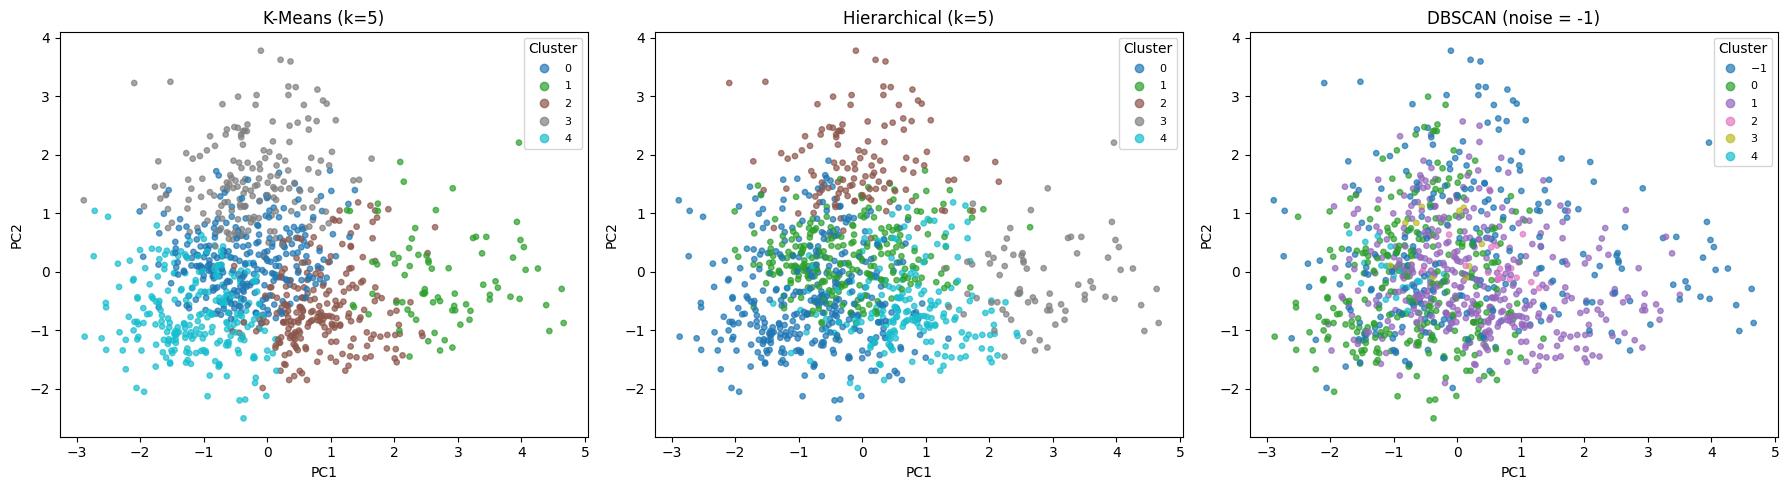

In [ ]:
from sklearn.decomposition import PCA

# 6A: how much variance does each component capture?
pca_full = PCA().fit(X)
ratio = pca_full.explained_variance_ratio_
cum = np.cumsum(ratio)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(ratio) + 1), ratio, label="Individual")
ax.plot(range(1, len(ratio) + 1), cum, "o-", color="black", label="Cumulative")
ax.axhline(0.9, ls="--", color="grey"); ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio"); ax.legend(); ax.set_title("PCA explained variance")
plt.show()
print(ratio.round(3)); print(cum.round(3))

# 6B: 2D projection
pca2 = PCA(n_components=2)
X_pca = pca2.fit_transform(X)
print("2-component variance:", pca2.explained_variance_ratio_.sum().round(3))

# 6C: what do the components mean? (loadings)
loadings = pd.DataFrame(PCA(n_components=3).fit(X).components_.T,
                        index=X_final.columns, columns=["PC1", "PC2", "PC3"]).round(2)
display(loadings)

# 6D: scatter plots for each model
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, col, title in zip(ax, ["km_cluster", "hc_cluster", "db_cluster"],
                         ["K-Means (k=5)", "Hierarchical (k=5)", "DBSCAN (noise = -1)"]):
    sc = a.scatter(X_pca[:, 0], X_pca[:, 1], c=df[col], cmap="tab10", s=15, alpha=0.7)
    a.set_title(title); a.set_xlabel("PC1"); a.set_ylabel("PC2")
    a.legend(*sc.legend_elements(), title="Cluster", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import adjusted_rand_score

def evaluate(name, labels, X):
    mask = labels != -1                    # exclude DBSCAN noise
    n_clusters = len(set(labels[mask]))
    return {"Model": name, "Clusters": n_clusters, "Noise points": int((~mask).sum()),
            "Silhouette (higher better)": silhouette_score(X[mask], labels[mask]),
            "Davies-Bouldin (lower better)": davies_bouldin_score(X[mask], labels[mask]),
            "Calinski-Harabasz (higher better)": calinski_harabasz_score(X[mask], labels[mask])}

comparison = pd.DataFrame([
    evaluate("K-Means (k=5)", df["km_cluster"].values, X),
    evaluate("Hierarchical (Ward, k=5)", df["hc_cluster"].values, X),
    evaluate("DBSCAN (eps=1.0, min=10)", df["db_cluster"].values, X)]).round(3)
display(comparison)

# Optional: stability of K-Means across random seeds
base = df["km_cluster"].values
aris = [adjusted_rand_score(base, KMeans(5, n_init=10, random_state=s).fit(X).labels_) for s in range(1, 11)]
print("Mean ARI across seeds:", np.mean(aris).round(3), "min:", np.min(aris).round(3))
print("ARI K-Means vs Hierarchical:", round(adjusted_rand_score(base, df["hc_cluster"]), 3))

,Model,Clusters,Noise points,Silhouette (higher better),Davies-Bouldin (lower better),Calinski-Harabasz (higher better)
0,K-Means (k=5),5,0,0.206,1.408,255.887
1,"Hierarchical (Ward, k=5)",5,0,0.159,1.558,200.939
2,"DBSCAN (eps=1.0, min=10)",5,259,0.090,1.503,56.206


Mean ARI across seeds: 0.965 min: 0.939
ARI K-Means vs Hierarchical: 0.511


In [ ]:
profile = (df.groupby("km_cluster")
             .agg(products=("price", "size"),
                  median_price=("price", "median"),
                  median_sold=("sold", "median"),
                  median_available=("available", "median"),
                  median_days_since_update=("days_since_update", "median"))
             .round(1))
display(profile)

# Most common category and brand per cluster (the profiling-only variables)
print(pd.crosstab(df["km_cluster"], df["category"], normalize="index").round(2))
print(df.groupby("km_cluster")["Item_Name"].agg(lambda s: s.value_counts().head(3).index.tolist()))

,products,median_price,median_sold,median_available,median_days_since_update
km_cluster,,,,,
0,271,25.0,19.0,7.0,1.0
1,77,26.9,998.0,86.0,1.0
2,225,35.6,566.0,10.0,0.0
3,174,30.0,34.0,10.0,17.5
4,247,77.1,21.0,5.0,1.0


category    eau de cologne  eau de parfum  eau de toilette  fragrances  other  \
km_cluster                                                                      
0                     0.06           0.25             0.40        0.10   0.09   
1                     0.09           0.14             0.74        0.00   0.03   
2                     0.07           0.17             0.69        0.00   0.04   
3                     0.06           0.32             0.45        0.00   0.11   
4                     0.03           0.54             0.22        0.02   0.10   

category    parfum  perfume  
km_cluster                   
0             0.01     0.09  
1             0.00     0.00  
2             0.01     0.02  
3             0.01     0.04  
4             0.03     0.06  
km_cluster
0            [Unbranded, Giorgio Armani, Ralph Lauren]
1                 [Ralph Lauren, Liz Claiborne, Armaf]
2                [Giorgio Armani, Armaf, Ralph Lauren]
3         [Ralph Lauren, Paco Rabanne, Giorgio

,% products,% units,% revenue
km_cluster,,,
0,27.3,1.4,0.8
1,7.7,19.0,14.5
2,22.6,75.5,77.3
3,17.5,2.4,2.1
4,24.8,1.7,5.3


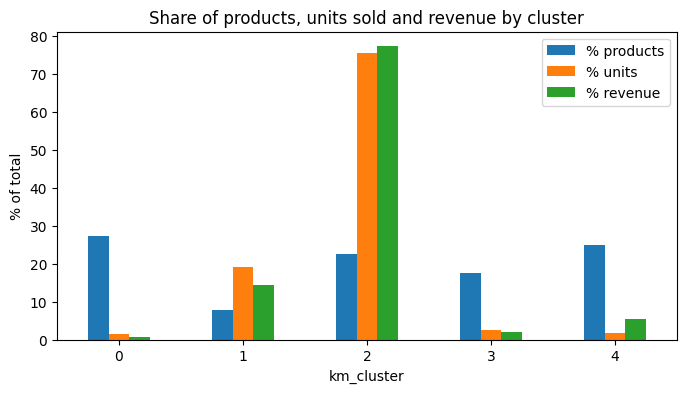

km_cluster
0    0.00
1    0.09
2    0.01
3    0.78
4    0.06
Name: days_since_update, dtype: float64


In [ ]:
df["revenue"] = df["price"] * df["sold"]          # proxy: current price × lifetime units sold
share = df.groupby("km_cluster").agg(products=("sold", "size"), units=("sold", "sum"), revenue=("revenue", "sum"))
for c in ["products", "units", "revenue"]:
    share["% " + c] = (share[c] / share[c].sum() * 100).round(1)
display(share[["% products", "% units", "% revenue"]])

share[["% products", "% units", "% revenue"]].plot(kind="bar", figsize=(8, 4))
plt.ylabel("% of total"); plt.title("Share of products, units sold and revenue by cluster")
plt.xticks(rotation=0); plt.show()

print((df["days_since_update"] >= 10).groupby(df["km_cluster"]).mean().round(2))   # share of stale listings